<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Título del proyecto -->
            Prospectivity for "U - REE" - Peru Central
        </strong>
    </span>
    <br>
    <span style="font-size:16px">
        Integración de variables y modelos de prospectividad para uranio y tierras raras
    </span>
    <br><br>
    <span>
        <!-- Repositorio del proyecto -->
        <a href="https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central" target="_blank">
            <img src="https://img.shields.io/badge/GitHub-repositorio-181717?logo=github">
        </a>
        &nbsp;&nbsp;
        <!-- Abrir en Colab -->
        <a href="https://colab.research.google.com/github/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central/blob/main/cuadernos/GC04_modelo_prospectividad.ipynb" target="_blank">
            <img src="https://colab.research.google.com/assets/colab-badge.svg">
        </a>
        &nbsp;&nbsp;
        <!-- Versión de Python -->
        <img src="https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white">
        &nbsp;&nbsp;
        <!-- scikit-learn -->
        <img src="https://img.shields.io/badge/scikit--learn-1.9-F7931E?logo=scikitlearn&logoColor=white">
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/badge/licencia-MIT-forestgreen">
    </span>
    <br>
    <span>
        <!-- Curso -->
        <img src="https://img.shields.io/badge/PUCP-Geocomputaci%C3%B3n%201GEO20-1d3557">
        &nbsp;&nbsp;
        <!-- Semestre -->
        <img src="https://img.shields.io/badge/semestre-2026--II-e8761a">
    </span>
    <br>
    <span>
        <strong>Carlos Manuel Gutiérrez Cruzado</strong> &nbsp;|&nbsp; <strong>Félix Bryan Cordero Escobar</strong>
    </span>
    <br>
    <span>Pontificia Universidad Católica del Perú</span>
</div>

***

<span style="color:#e8761a; font-size:25px">**GC04 - Integración de variables y modelos de prospectividad**</span>

Entrega final del Trabajo Final de **Geocomputación (1GEO20)**, semestre 2026-II.

En GC02 y GC03 se evaluó qué fuentes son confiables y con qué variables se relaciona el uranio. Con esos resultados,
en este cuaderno se entrenan <span style="color:#2a9d8f">cinco algoritmos de aprendizaje automático</span>, validados
por bloques espaciales, y se obtienen <span style="color:#2a9d8f">mapas de favorabilidad</span> para uranio y tierras
raras (ΣREE) en la Cordillera Oriental del Perú central y las <span style="color:#2a9d8f">zonas prioritarias</span>
donde coinciden.

<span style="color:#2a9d8f; font-size:20px">**Contenido**</span>

***
- [Descripción general](#descripcion)
- [1. Librerías y datos](#parte-1)
- [2. Integración de las variables](#parte-2)
- [3. Etiquetas y separación de cada variable](#parte-3)
- [4. Validación por bloques espaciales](#parte-4)
- [5. Conjunto de variables](#parte-5)
- [6. Cinco modelos con validación anidada](#parte-6)
- [7. Qué variables usan los modelos](#parte-7)
- [8. Mapas de favorabilidad y consenso](#parte-8)
- [9. Franja de prueba y prueba contra el azar espacial](#parte-9)
- [10. Zonas prioritarias para U y ΣREE](#parte-10)
- [11. Conclusiones](#parte-11)
- [Declaración de uso de inteligencia artificial](#ia)
- [Referencias](#referencias)

***

<a id="descripcion"></a>

## <span style="color:#e8761a">**DESCRIPCIÓN GENERAL**</span>
***

### Objetivo

Estimar dónde es más favorable encontrar rocas enriquecidas en uranio y en tierras raras dentro del área de estudio, a
partir de variables públicas, y comparar esa estimación con la que da el mapa geológico.

### Enfoque

En el Perú no hay radiometría aérea pública, que es la herramienta usual para explorar uranio. Por eso se sigue un
enfoque de **sistema mineral**: cada variable representa un componente del proceso que concentra el U y las REE, y un
modelo aprende cómo se combinan en las rocas que ya están analizadas.

| Componente del sistema | Variables | Fuente |
|---|---|---|
| Fuente (magmas diferenciados) | Clase de roca, pulso intrusivo, litología félsica, distancia al Permotriásico | Geología 1:50 000 de INGEMMET y edades U-Pb |
| Camino (estructuras) | Distancia y densidad de fallas y pliegues | INGEMMET |
| Huella geoquímica | La, Y, Be y K en sedimentos de quebrada (promedio gaussiano y por cuenca) | INGEMMET (GC03) |
| Geofísica | Anomalía de Bouguer XGM2019e, anomalía magnética EMAG2 y su gradiente | GC02; Meyer et al. (2017) |
| Relieve y superficie | Elevación, pendiente, rugosidad, razones de Landsat 8/9 | Copernicus GLO-90; USGS |

### Decisiones tomadas a partir de GC02 y GC03

| Resultado de GC02 y GC03 | Decisión en GC04 |
|---|---|
| XGM2019e reproduce el patrón regional de las estaciones, pero no los detalles locales | Se usa la grilla del modelo como variable regional; la anomalía residual se evalúa como posible artefacto (sección 3) |
| BDG 2022 da más U que la litogeoquímica en rocas básicas de labores mineras y usa en parte digestión parcial | El umbral de U se fija con un criterio geológico externo y cada afloramiento duplicado pesa 1 |
| El Be del sedimento cercano se relaciona con el U de la roca (ρ ≈ 0,4) y cubre zonas sin rocas analizadas | Los sedimentos entran como variables en todo el área |
| La correlación entre U y gravedad desaparece al controlar la posición | La gravedad no se interpreta sola; se mide su aporte dentro del modelo |

| Técnica | Sección |
|---|---|
| Promedio gaussiano, remuestreo por promedio y comprobación contra los datos del repositorio | 2 |
| AUC univariada y control de variables que reflejan el muestreo | 3 |
| Validación cruzada por bloques espaciales de 32 km | 4 |
| Regresión logística, SVM, Random Forest, Gradient Boosting y red neuronal con validación anidada | 5 y 6 |
| Importancia por permutación y dependencia parcial | 7 |
| Mapas en percentiles, consenso entre modelos y clases de favorabilidad | 8 |
| Franja de prueba y traslación toroidal de las etiquetas | 9 |
| Cruce de clases de U y ΣREE | 10 |

***

<a id="parte-1"></a>

## <span style="color:#e8761a">**1. LIBRERÍAS Y DATOS**</span>
***

Si el cuaderno se abre en Google Colab, la primera celda descarga el repositorio y las tres librerías que Colab no trae.
En una instalación local con `uv sync` no hace nada.

In [1]:
'''Solo en Google Colab: repositorio y librerías que faltan'''
import sys
if 'google.colab' in sys.modules:
    import subprocess
    subprocess.run(['git', 'clone', '-q', '--depth', '1',
                    'https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central.git'], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio', 'cmcrameri', 'matplotlib-scalebar'],
                   check=True)
    sys.path.insert(0, 'Prospectivity-for-U-REE-Peru-Central')

In [2]:
'''Importamos las librerías que usaremos'''

import time
import warnings

import numpy as np                           # Cálculo numérico
import pandas as pd                          # Tablas
import geopandas as gpd                      # Vectores (SHP)
from scipy import stats                      # Estadística
import matplotlib.pyplot as plt              # Gráficos
from matplotlib.colors import ListedColormap, to_rgb
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import partial_dependence
from sklearn.metrics import average_precision_score, roc_auc_score
'''Funciones propias del trabajo (carpeta geocomp/)'''
from geocomp import lectura, espacial, modelo
from geocomp import graficos as graf
from geocomp.rutas import ARCHIVOS, RESULTADOS

'''Estilo común de las figuras'''
graf.aplicar_estilo()
pd.set_option('display.precision', 3)
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
INICIO = time.time()

In [3]:
'''Tabla de rocas con etiquetas y variables, catálogo de las 40 variables y franja de prueba'''
tabla = modelo.cargar_rocas()
catalogo = modelo.cargar_catalogo()
familia = catalogo.set_index('variable').familia
aoi = lectura.cargar_aoi()
franja = gpd.read_file(ARCHIVOS['franja_prueba']).to_crs(aoi.crs)
elevacion, ext_relieve = espacial.raster_a_utm(ARCHIVOS['dem_90m'], aoi, celda=250)

print(f'Rocas: {len(tabla)} | entrenamiento: {(tabla.conjunto == "entrenamiento").sum()} | '
      f'franja de prueba: {(tabla.conjunto == "prueba").sum()}')
print(f'Variables: {len(catalogo)} en {catalogo.familia.nunique()} familias')
tabla.groupby(['conjunto', 'fuente']).size().unstack(0)

Rocas: 794 | entrenamiento: 614 | franja de prueba: 180
Variables: 40 en 7 familias


conjunto,entrenamiento,prueba
fuente,,
BDG 2022,303,79
Litogeoquímica INGEMMET,280,78
Materia prima crítica (GE27),31,23


La franja de prueba es un rectángulo de 20 km al sur del área que se separó antes de explorar los datos. Ninguna
decisión del cuaderno la usa: se evalúa una sola vez, en la sección 9.

***

<a id="parte-2"></a>

## <span style="color:#e8761a">**2. INTEGRACIÓN DE LAS VARIABLES**</span>
***

Todas las variables están en la misma grilla de 250 m (440 × 560 celdas, WGS 84 / UTM 18S), que es la resolución a la
que se dibujan los mapas finales. Cada variable es un GeoTIFF en `datos/modelo/variables/`, y la tabla
`rocas_variables.csv` guarda su valor en la ubicación de cada roca.

In [4]:
'''Variables por familia y porcentaje del área con dato'''
resumen = catalogo.groupby('familia').agg(variables=('variable', 'count'), con_dato=('pct_area', 'min'))
resumen['ejemplos'] = catalogo.groupby('familia').variable.apply(lambda v: ', '.join(v.head(4)))
resumen.rename(columns={'con_dato': '% mínimo del área con dato'})

,variables,% mínimo del área con dato,ejemplos
familia,,,
Estructural,4,100.0,"dist_falla_km, dens_falla, dist_falla_regional..."
Geofísica,6,54.9,"gravedad_bouguer, grav_dist_estacion_km, grav_..."
Geología,12,100.0,"clase_intrusivo, clase_volcanico, clase_sedime..."
Landsat,4,99.0,"ls_oxidos_fe, ls_arcillas, ls_ferroso, ls_ndvi"
Relieve,3,100.0,"elevacion, pendiente, rugosidad"
Sedimentos,6,79.4,"sed_La, sed_Y, sed_Be, sed_K"
Sedimentos (cuenca),5,70.8,"cue_La, cue_Y, cue_Be, cue_K"


Tres variables se pueden rehacer desde los datos de este repositorio: el Be de los sedimentos (promedio gaussiano de
2,5 km con radio máximo de 7,5 km sobre el log10 del Be), la anomalía de Bouguer de XGM2019e (remuestreo bilineal) y la
elevación (promedio de los píxeles de 90 m en cada celda de 250 m). Si la integración es reproducible, deben coincidir
con las variables del modelo.

In [5]:
'''Reconstrucción de tres variables a partir de los datos de GC01-GC03'''
sedimentos = lectura.cargar_sedimentos()
con_be = sedimentos[sedimentos.Be_ppm > 0]
be, densidad = espacial.promedio_gaussiano(con_be, np.log10(con_be.Be_ppm), aoi, celda=250, banda=2500,
                                           radio_max=7500)
xgm, _ = espacial.raster_a_utm(ARCHIVOS['gravedad_xgm2019e'], aoi, celda=250, margen=0)
dem, _ = espacial.raster_a_utm(ARCHIVOS['dem_90m'], aoi, celda=250, margen=0, metodo='promedio')

filas = []
for nombre, rehecha in [('sed_Be', be), ('grav_XGM2019e', xgm), ('elevacion', dem)]:
    original = modelo.leer_variable(nombre)[0]
    ok = np.isfinite(original) & np.isfinite(rehecha)
    filas.append({'variable': nombre, 'celdas comparadas': ok.sum(),
                  'r de Pearson': stats.pearsonr(original[ok], rehecha[ok])[0],
                  'diferencia máxima': np.abs(original[ok] - rehecha[ok]).max(),
                  'celdas con dato distinto': (np.isfinite(original) != np.isfinite(rehecha)).sum()})
pd.DataFrame(filas).set_index('variable')

,celdas comparadas,r de Pearson,diferencia máxima,celdas con dato distinto
variable,,,,
sed_Be,195703,1.0,2.572e-03,0
grav_XGM2019e,246400,1.0,1.526e-05,0
elevacion,246400,1.0,2.441e-04,0


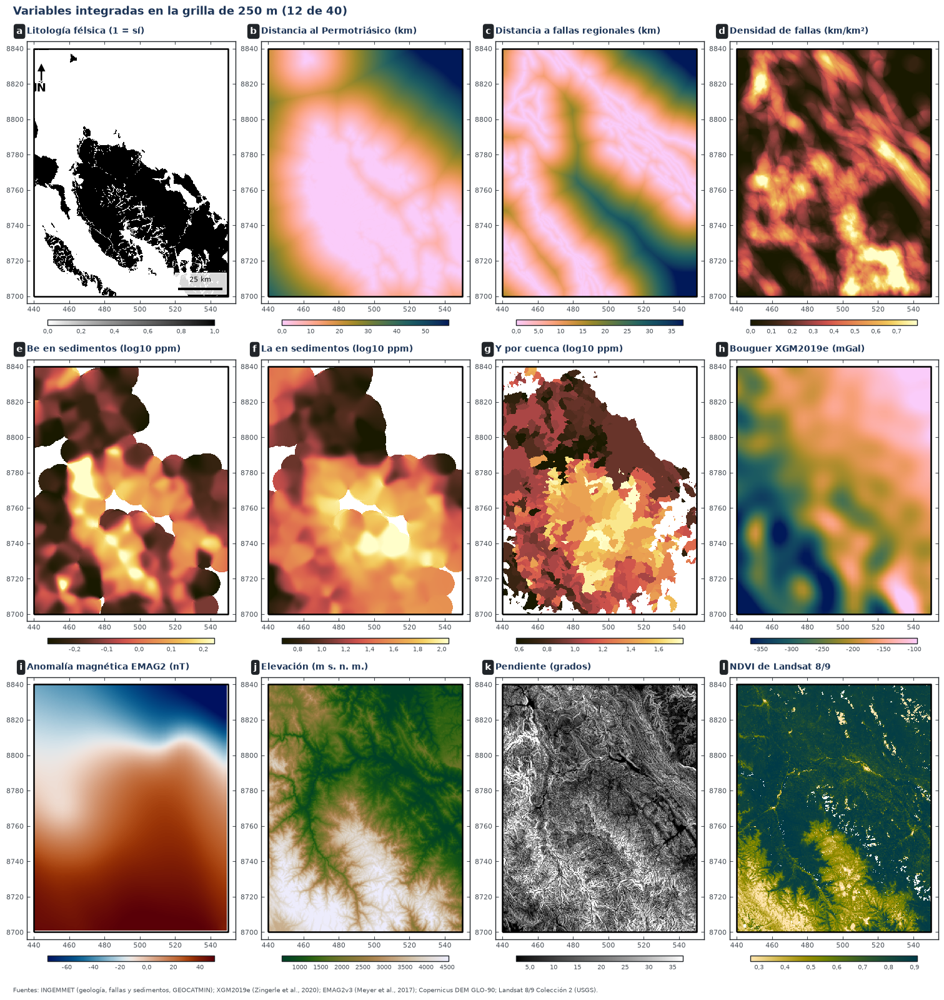

In [6]:
'''Figura 1: doce de las variables integradas, una o dos por familia'''

MUESTRA = [('litologia_felsica', 'Litología félsica (1 = sí)', 'cmc.grayC_r'),
           ('dist_PT_km', 'Distancia al Permotriásico (km)', 'cmc.batlow_r'),
           ('dist_falla_regional_km', 'Distancia a fallas regionales (km)', 'cmc.batlow_r'),
           ('dens_falla', 'Densidad de fallas (km/km²)', 'cmc.lajolla'),
           ('sed_Be', 'Be en sedimentos (log10 ppm)', 'cmc.lajolla'),
           ('sed_La', 'La en sedimentos (log10 ppm)', 'cmc.lajolla'),
           ('cue_Y', 'Y por cuenca (log10 ppm)', 'cmc.lajolla'),
           ('grav_XGM2019e', 'Bouguer XGM2019e (mGal)', graf.CMAP_CONTINUO),
           ('mag_EMAG2', 'Anomalía magnética EMAG2 (nT)', graf.CMAP_DIVERGENTE),
           ('elevacion', 'Elevación (m s. n. m.)', graf.CMAP_ELEVACION),
           ('pendiente', 'Pendiente (grados)', 'cmc.grayC'),
           ('ls_ndvi', 'NDVI de Landsat 8/9', 'cmc.bamako_r')]
fig, ejes = plt.subplots(3, 4, figsize=(15, 15.5), layout='constrained')
for ax, (nombre, rotulo, cmap), letra in zip(ejes.flat, MUESTRA, 'abcdefghijkl'):
    matriz, perfil = modelo.leer_variable(nombre)
    lim = np.nanpercentile(matriz, [2, 98])
    im = ax.imshow(matriz, extent=modelo.extension(perfil), cmap=cmap, vmin=lim[0], vmax=lim[1],
                   interpolation='nearest')
    graf.marco_mapa(ax, aoi, accesorios=(letra == 'a'))
    ax.set_title(f'{rotulo}', fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.grid(False)
    graf.letra(ax, letra)
    barra = fig.colorbar(im, ax=ax, orientation='horizontal', shrink=0.8, pad=0.02, aspect=30)
    barra.ax.tick_params(labelsize=7.5)
    barra.formatter = plt.FuncFormatter(lambda v, _: graf.numero_es(v, 1 if abs(v) < 10 else 0))
    barra.update_ticks()
fig.suptitle('Variables integradas en la grilla de 250 m (12 de 40)', x=0.01, ha='left', fontsize=13,
             fontweight='bold', color=graf.AZUL)
graf.fuente_figura(fig, 'Fuentes: INGEMMET (geología, fallas y sedimentos, GEOCATMIN); XGM2019e (Zingerle et al., '
                   '2020); EMAG2v3 (Meyer et al., 2017); Copernicus DEM GLO-90; Landsat 8/9 Colección 2 (USGS).')
graf.guardar(fig, 'GC04_01_variables_integradas.png')

**Lectura:** las tres variables reconstruidas coinciden con las del modelo en todas las celdas (r = 1,000; diferencia
máxima de 0,003 en log10 del Be, 0,00002 mGal en la gravedad y 0,0002 m en la elevación), y las celdas sin dato son las
mismas. La integración, por lo tanto, se puede repetir desde los datos del repositorio.

La figura 1 muestra que las variables cubren escalas muy distintas: la geología y las fallas tienen detalle de 250 m,
los sedimentos suavizan unos 2,5 km y dejan vacíos donde no hay muestras (20 % del área), y la gravedad y el
magnetismo varían a escala de decenas de kilómetros. El NDVI confirma que la mayor parte del área está cubierta de
selva (valores de 0,8 a 0,9), lo que limita a Landsat como indicador de alteración.

***

<a id="parte-3"></a>

## <span style="color:#e8761a">**3. ETIQUETAS Y SEPARACIÓN DE CADA VARIABLE**</span>
***

Un modelo de clasificación necesita saber qué es un positivo. Se usan dos etiquetas, fijadas con criterios geológicos
y no con la distribución de los datos del área:

| Etiqueta | Positivo | Criterio | Rocas aptas |
|---|---|---|---|
| U | U ≥ 6,7 ppm | Unas dos veces el U de un granito promedio (Cuney, 2014) | Rocas ígneas y metamórficas con U medido |
| ΣREE | ΣREE ≥ 478 ppm | Percentil 85 de las rocas aptas; con el percentil 90 quedan muy pocos positivos para validar | Rocas con las 14 REE medidas |

Antes de entrenar, la **AUC univariada** mide cuánto separa cada variable, sola, las rocas positivas de las
negativas: 0,5 es el azar y 1 la separación perfecta (se reporta max(AUC, 1 − AUC), con el signo de la relación).

In [7]:
'''Rocas de entrenamiento por etiqueta'''
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y = modelo.conjunto(tabla, etiqueta)
    dp, yp = modelo.conjunto(tabla, etiqueta, 'prueba')
    print(f'{nombre}: {len(d)} rocas de entrenamiento ({y.sum()} positivas, {d.peso.sum():.0f} afloramientos) | '
          f'franja de prueba: {len(dp)} ({yp.sum()} positivas)')

U: 426 rocas de entrenamiento (117 positivas, 347 afloramientos) | franja de prueba: 107 (16 positivas)
ΣREE: 377 rocas de entrenamiento (60 positivas, 312 afloramientos) | franja de prueba: 88 (4 positivas)


In [8]:
'''AUC univariada de cada variable (ponderada por afloramiento)'''
def auc_univariada(etiqueta):
    d, y = modelo.conjunto(tabla, etiqueta)
    filas = {}
    for v in catalogo.variable:
        ok = d[v].notna().values
        auc = roc_auc_score(y[ok], d.loc[ok, v], sample_weight=d.peso[ok])
        filas[v] = {'AUC': max(auc, 1 - auc), 'signo': '+' if auc >= 0.5 else '−', 'rocas con dato': ok.sum()}
    return pd.DataFrame(filas).T

separacion = {nombre: auc_univariada(et) for et, nombre in modelo.ETIQUETAS.items()}
pd.concat(separacion, axis=1).sort_values(('U', 'AUC'), ascending=False).head(10)

U                        ΣREE                     
                     AUC signo rocas con dato    AUC signo rocas con dato
sed_Be             0.807     +            422  0.741     +            375
dist_san_ramon_km   0.77     −            426  0.518     −            377
sed_Y              0.712     +            422  0.783     +            375
sed_La_Y           0.705     −            422  0.585     −            375
dist_PT_km         0.685     −            426  0.656     −            377
mag_gradiente      0.673     +            425  0.556     −            376
grav_XGM2019e      0.669     −            426  0.503     −            377
sed_densidad        0.65     +            426  0.527     +            377
pulso_PT           0.646     +            426   0.62     +            377
elevacion          0.644     −            426  0.506     −            377

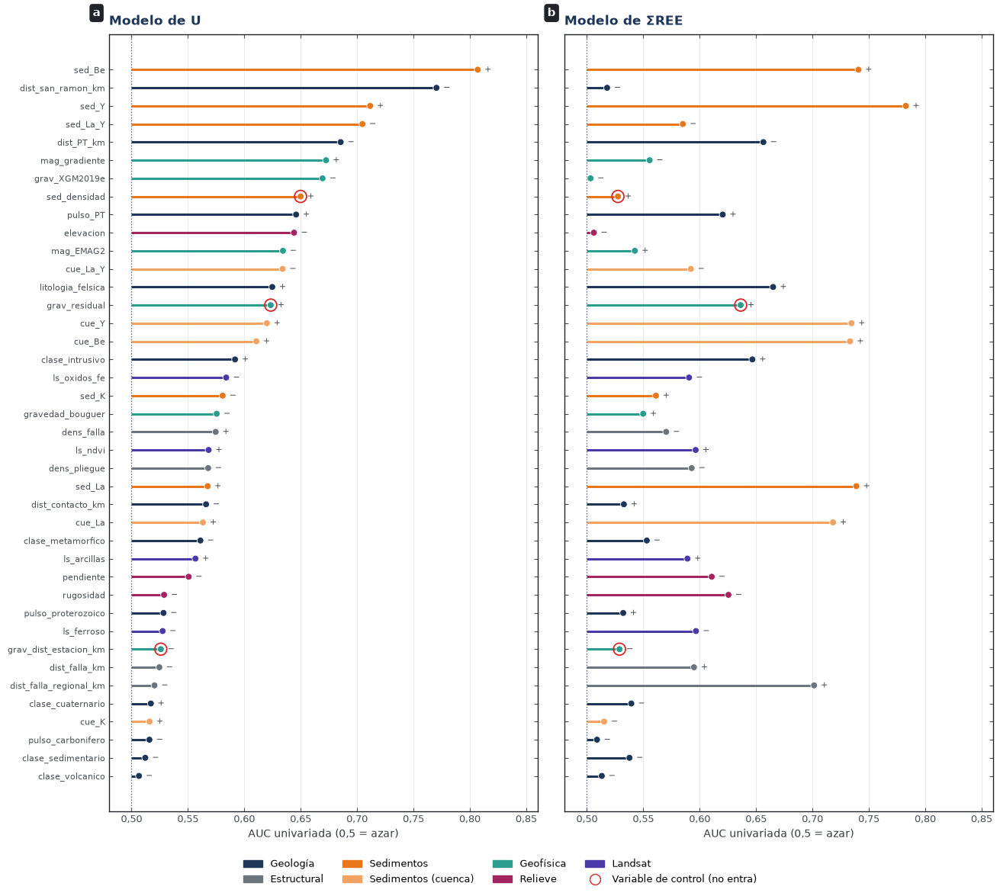

In [9]:
'''Figura 2: AUC univariada de las 40 variables para U y ΣREE'''

COLOR_FAMILIA = {'Geología': '#1d3557', 'Estructural': '#6c757d', 'Sedimentos': '#e8761a',
                 'Sedimentos (cuenca)': '#f4a261', 'Geofísica': '#2a9d8f', 'Relieve': '#a3245e', 'Landsat': '#4a3aa7'}
orden = separacion['U'].AUC.astype(float).sort_values().index
fig, ejes = plt.subplots(1, 2, figsize=(13, 11), sharey=True, layout='constrained')
for ax, (nombre, tab), letra in zip(ejes, separacion.items(), 'ab'):
    tab = tab.loc[orden]
    colores = [COLOR_FAMILIA[familia[v]] for v in orden]
    ax.hlines(range(len(orden)), 0.5, tab.AUC.astype(float), color=colores, lw=2.2)
    ax.scatter(tab.AUC.astype(float), range(len(orden)), c=colores, s=40, zorder=3, edgecolor='white', lw=0.6)
    for i, (v, fila) in enumerate(tab.iterrows()):
        ax.text(float(fila.AUC) + 0.006, i, fila.signo, va='center', fontsize=8, color=graf.GRIS)
    control = [orden.get_loc(v) for v in modelo.CONTROL]
    ax.scatter(tab.AUC.astype(float).iloc[control], control, s=130, facecolor='none', edgecolor='#d62828', lw=1.3,
               zorder=4)
    ax.axvline(0.5, color=graf.COLOR_REF, ls=':', lw=1)
    ax.set_xlim(0.48, 0.86)
    ax.set_yticks(range(len(orden)), orden, fontsize=8)
    ax.set_xlabel('AUC univariada (0,5 = azar)')
    ax.set_title(f'Modelo de {nombre}')
    graf.ejes_coma_decimal(ax, y=False, d=2)
    ax.grid(axis='y', visible=False)
    graf.letra(ax, letra)
fig.legend(handles=[Patch(color=c, label=f) for f, c in COLOR_FAMILIA.items()] +
           [Line2D([], [], marker='o', ls='', mfc='none', mec='#d62828', ms=10, label='Variable de control (no entra)')],
           loc='lower center', bbox_to_anchor=(0.5, -0.06), ncol=4, frameon=False)
graf.guardar(fig, 'GC04_02_separacion_univariada.png', svg=True)

Tres variables describen el muestreo y no la geología: la **densidad de sedimentos**, la **distancia a la estación
gravimétrica** más cercana y la **anomalía residual** (estaciones interpoladas menos XGM2019e). Una variable así puede
separar bien las clases solo porque los geólogos muestrean más cerca de las rocas interesantes. Se comprueba su relación
con la densidad de muestreo y con la elevación en las celdas del área:

In [10]:
'''Relación de las variables de control con el muestreo y el relieve (Spearman sobre 20 000 celdas al azar)'''
rng = np.random.default_rng(modelo.SEMILLA)
celdas = rng.choice(np.flatnonzero(np.isfinite(modelo.leer_variable('elevacion')[0]).ravel()), 20_000,
                    replace=False)
valores = pd.DataFrame({v: modelo.leer_variable(v)[0].ravel()[celdas]
                        for v in ['grav_residual', 'grav_XGM2019e', 'sed_Be', 'sed_densidad', 'grav_dist_estacion_km',
                                  'elevacion']})
valores.corr(method='spearman').loc[['grav_residual', 'grav_XGM2019e', 'sed_Be'],
                                    ['sed_densidad', 'grav_dist_estacion_km', 'elevacion']]

,sed_densidad,grav_dist_estacion_km,elevacion
grav_residual,0.217,-0.169,-0.285
grav_XGM2019e,-0.522,0.259,-0.502
sed_Be,0.166,0.044,0.051


**Lectura:** el Be de los sedimentos es la variable que mejor separa las rocas con U alto (AUC = 0,81) y también es de
las mejores para ΣREE (0,74), lo que confirma con otra técnica la relación encontrada en GC03. Para ΣREE la variable
más fuerte es el Y de los sedimentos (0,78), seguido del La y de la versión por cuenca de los mismos elementos (0,72 a
0,74). La distancia al Sienogranito San Ramón separa bien el U (0,77) pero no las REE (0,52): el U positivo está
concentrado en ese plutón, mientras que las REE altas se reparten en un área más amplia.

La anomalía de Bouguer de XGM2019e separa el U con AUC = 0,67 y signo negativo, es decir, el U es más alto donde la
anomalía es más negativa, como se espera sobre granitos de baja densidad. Sin embargo, también se correlaciona con la
densidad de sedimentos (ρ = −0,52) y con la elevación (−0,50), de modo que su aporte debe leerse junto con el gradiente
oeste-este descrito en GC03.

Las tres variables de control separan las clases (AUC de 0,53 a 0,65), y precisamente por eso no entran a los modelos:
una variable de muestreo con buena AUC indica sesgo y no geología. La anomalía residual, además, solo existe a menos
de 15 km de una estación (55 % del área) y, según GC02, la diferencia entre las estaciones y el modelo depende de la
elevación; su señal es sobre todo el error de la reducción de Bouguer y no un cuerpo geológico.

***

<a id="parte-4"></a>

## <span style="color:#e8761a">**4. VALIDACIÓN POR BLOQUES ESPACIALES**</span>
***

Si las rocas de evaluación están al lado de rocas de entrenamiento, el modelo acierta por cercanía y no porque haya
aprendido una relación geológica: la validación cruzada al azar es optimista cuando los datos tienen autocorrelación
espacial (Roberts et al., 2017). Por eso las rocas se agrupan en **bloques de 32 km** y cada bloque entero va a un solo
pliegue. Los duplicados de un mismo afloramiento quedan juntos, aunque crucen el borde de un bloque.

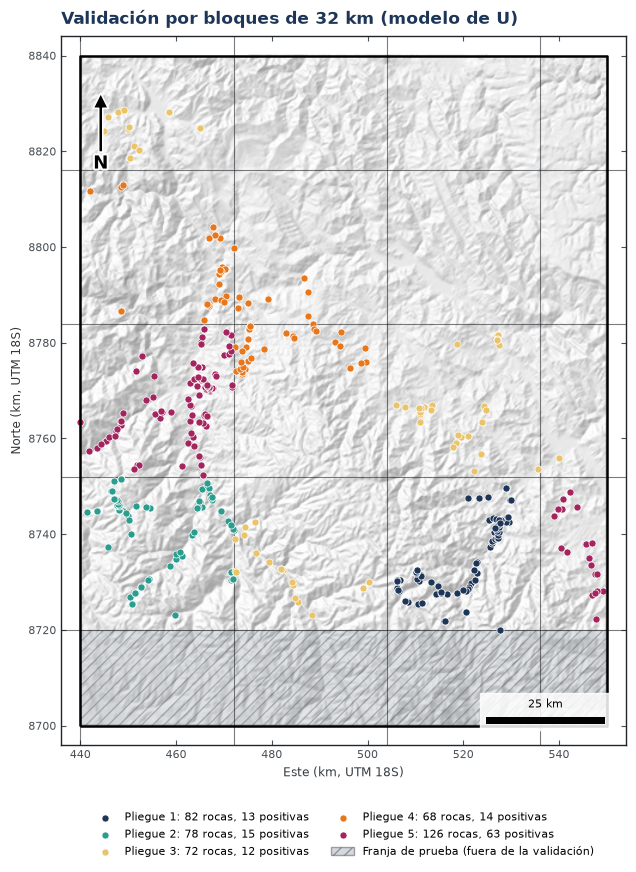

In [11]:
'''Figura 3: pliegues de la validación del modelo de U'''

d, y = modelo.conjunto(tabla, 'U_pos')
pl, grupos = modelo.pliegues(d, y)
pliegue = np.zeros(len(d), int)
for k, (_, te) in enumerate(pl):
    pliegue[te] = k + 1

fig, ax = plt.subplots(figsize=(7.5, 9.2))
graf.relieve(ax, elevacion, ext_relieve, opacidad=0.5)
franja.plot(ax=ax, facecolor='#adb5bd', edgecolor='#495057', hatch='///', alpha=0.35, lw=0.8, zorder=2)
COLORES_PLIEGUE = ['#1d3557', '#2a9d8f', '#e9c46a', '#e8761a', '#a3245e']
for k in range(len(pl)):
    s = pliegue == k + 1
    ax.scatter(d.x[s], d.y[s], s=26, color=COLORES_PLIEGUE[k], edgecolor='white', lw=0.5, zorder=5,
               label=f'Pliegue {k + 1}: {s.sum()} rocas, {int(y[s].sum())} positivas')
for xv in np.arange(d.x.min(), aoi.total_bounds[2], modelo.LADO_BLOQUE):
    ax.axvline(xv, color='#212529', lw=0.8, alpha=0.6, zorder=3)
for yv in np.arange(d.y.min(), aoi.total_bounds[3], modelo.LADO_BLOQUE):
    ax.axhline(yv, color='#212529', lw=0.8, alpha=0.6, zorder=3)
graf.marco_mapa(ax, aoi, f'Validación por bloques de 32 km (modelo de U)')
ax.grid(False)
h, l = ax.get_legend_handles_labels()
h.append(Patch(facecolor='#adb5bd', edgecolor='#495057', hatch='///', alpha=0.5))
l.append('Franja de prueba (fuera de la validación)')
ax.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8, frameon=False)
graf.guardar(fig, 'GC04_03_bloques_validacion.png')

**Lectura:** las 426 rocas del modelo de U quedan en cinco pliegues de 68 a 126 rocas. El pliegue 5 concentra 63 de
las 117 positivas, porque casi todas pertenecen al Sienogranito San Ramón, que ocupa uno o dos bloques. No es posible
repartir ese cúmulo sin separar rocas vecinas, y es la razón por la que las métricas varían bastante de un pliegue a
otro en la sección 6. Cuando se evalúa ese pliegue, el modelo debe reconocer San Ramón sin haber visto casi ninguna
de sus rocas.

***

<a id="parte-5"></a>

## <span style="color:#e8761a">**5. CONJUNTO DE VARIABLES**</span>
***

Los sedimentos están en dos versiones, el promedio gaussiano (`sed_*`) y el promedio por cuenca de drenaje (`cue_*`).
Usar las dos duplicaría la misma información. Además, Landsat puede reflejar la vegetación de la selva más que la
alteración de las rocas. Para cada etiqueta se elige el conjunto con mejor PR-AUC en la validación por bloques con un
Random Forest de referencia. La elección no usa la franja de prueba.

In [12]:
'''Cuatro conjuntos candidatos (sin las variables de control)'''
TODAS = [v for v in catalogo.variable if v not in modelo.CONTROL]
GAUSS = [v for v in TODAS if not v.startswith('cue_')]
CUENCA = [v for v in TODAS if not v.startswith('sed_')]
CONJUNTOS = {'Sedimentos gaussianos': GAUSS, 'Sedimentos por cuenca': CUENCA,
             'Gaussianos sin Landsat': [v for v in GAUSS if not v.startswith('ls_')],
             'Por cuenca sin Landsat': [v for v in CUENCA if not v.startswith('ls_')]}

filas = []
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y = modelo.conjunto(tabla, etiqueta)
    pl, _ = modelo.pliegues(d, y)
    for conjunto, variables in CONJUNTOS.items():
        p = np.zeros(len(d))
        for tr, te in pl:
            rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                        n_jobs=-1, random_state=modelo.SEMILLA)
            rf.fit(d.loc[tr, variables].values, y[tr], sample_weight=d.peso.values[tr])
            p[te] = rf.predict_proba(d.loc[te, variables].values)[:, 1]
        filas.append({'etiqueta': nombre, 'conjunto': conjunto, 'variables': len(variables),
                      'ROC-AUC': roc_auc_score(y, p, sample_weight=d.peso),
                      'PR-AUC': average_precision_score(y, p, sample_weight=d.peso)})
seleccion = pd.DataFrame(filas)

'''Se elige por PR-AUC, la métrica principal cuando los positivos son pocos'''
VARS = {}
for etiqueta, nombre in modelo.ETIQUETAS.items():
    mejor = seleccion[seleccion.etiqueta == nombre].sort_values('PR-AUC').conjunto.iloc[-1]
    VARS[etiqueta] = CONJUNTOS[mejor]
    print(f'{nombre}: {mejor} ({len(VARS[etiqueta])} variables)')
seleccion.set_index(['etiqueta', 'conjunto'])

U: Gaussianos sin Landsat (28 variables)
ΣREE: Por cuenca sin Landsat (28 variables)


variables  ROC-AUC  PR-AUC
etiqueta conjunto                                          
U        Sedimentos gaussianos          32    0.762   0.533
         Sedimentos por cuenca          32    0.736   0.522
         Gaussianos sin Landsat         28    0.764   0.542
         Por cuenca sin Landsat         28    0.746   0.531
ΣREE     Sedimentos gaussianos          32    0.765   0.284
         Sedimentos por cuenca          32    0.745   0.294
         Gaussianos sin Landsat         28    0.758   0.281
         Por cuenca sin Landsat         28    0.747   0.309

**Lectura:** el modelo de U funciona algo mejor con los sedimentos gaussianos (PR-AUC de 0,53 a 0,54 frente a 0,52 a
0,53 por cuenca) y el de ΣREE con la versión por cuenca (0,29 a 0,31 frente a 0,28). Quitar Landsat casi no cambia el
resultado (diferencias de 0,01 a 0,02), lo que es coherente con la cobertura vegetal vista en la sección 2. Las
diferencias son pequeñas frente a la variación entre pliegues, así que la elección importa poco; se adopta la de mejor
PR-AUC con 28 variables en cada caso.

***

<a id="parte-6"></a>

## <span style="color:#e8761a">**6. CINCO MODELOS CON VALIDACIÓN ANIDADA**</span>
***

Se entrenan cinco algoritmos distintos con las mismas reglas, porque uno solo puede dar buenos resultados por un sesgo
propio:

| Modelo | Idea | Hiperparámetros probados |
|---|---|---|
| Regresión logística | Suma ponderada de las variables | C: 0,01; 0,1; 1 |
| SVM (núcleo RBF) | Frontera de máxima separación en un espacio transformado | C: 0,3; 1; 3; γ: scale; 0,03 |
| Random Forest | Promedio de 300 árboles con datos y variables al azar | hoja mínima: 3; 10; variables por división: √p; 0,5 |
| Gradient Boosting | Árboles en secuencia que corrigen los errores del anterior | tasa: 0,03; 0,1; profundidad: 2; 4 |
| Red neuronal (MLP) | Capas de neuronas que combinan las variables | capas: (16); (32, 16); α: 0,01; 0,1 |

La validación es **anidada**: el nivel externo (5 pliegues de bloques) mide el desempeño y el interno (3 pliegues de
bloques, solo dentro del entrenamiento) elige los hiperparámetros. Así los hiperparámetros nunca se eligen mirando las
rocas con que se evalúan. Cada modelo se compara con una **línea base geológica**, la tasa de positivos de cada grupo
geológico del mapa: un modelo tiene habilidad solo si supera a la línea base en PR-AUC, que es la métrica adecuada
cuando los positivos son pocos (Saito y Rehmsmeier, 2015).

In [13]:
'''Validación anidada de los cinco modelos para U y ΣREE (unos dos minutos)'''
VALIDACION, METRICAS, HABILES = {}, {}, {}
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y = modelo.conjunto(tabla, etiqueta)
    pl, grupos = modelo.pliegues(d, y)
    pred, ajustados, parametros = modelo.validacion_anidada(d, y, VARS[etiqueta], pl, grupos)
    VALIDACION[etiqueta] = (d, y, pl, pred, ajustados, parametros)
    METRICAS[etiqueta] = modelo.metricas(d, y, pl, pred)
    HABILES[etiqueta] = modelo.habiles(METRICAS[etiqueta])
    print(f'{nombre}: modelos con habilidad: {", ".join(HABILES[etiqueta])}')
pd.concat({modelo.ETIQUETAS[e]: m for e, m in METRICAS.items()}).drop(columns='prevalencia')

U: modelos con habilidad: SVM, Random Forest, Red neuronal


ΣREE: modelos con habilidad: Regresión logística, SVM, Random Forest, Gradient Boosting, Red neuronal


ROC-AUC  ROC-AUC desv.  PR-AUC  PR-AUC desv.  Brier
     modelo                                                                   
U    Línea base geológica    0.609          0.075   0.430         0.156  0.184
     Regresión logística     0.668          0.106   0.396         0.053  0.220
     SVM                     0.696          0.159   0.434         0.242  0.180
     Random Forest           0.752          0.180   0.535         0.236  0.167
     Gradient Boosting       0.634          0.126   0.374         0.135  0.212
     Red neuronal            0.722          0.137   0.452         0.223  0.197
ΣREE Línea base geológica    0.515          0.109   0.154         0.074  0.133
     Regresión logística     0.629          0.053   0.197         0.110  0.224
     SVM                     0.619          0.145   0.255         0.120  0.124
     Random Forest           0.719          0.159   0.301         0.194  0.135
     Gradient Boosting       0.737          0.114   0.334         0.175  0.140
     Red neuronal            0.708          0.165   0.262         0.119  0.169

In [14]:
'''Hiperparámetros elegidos en cada pliegue externo (si cambian mucho, el modelo es inestable)'''
parametros = {(modelo.ETIQUETAS[e], m, k + 1): str(p) for e, v in VALIDACION.items() for (m, k), p in v[5].items()}
pd.Series(parametros).unstack(2)

1  \
U    Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 4}   
     Random Forest          {'max_features': 'sqrt', 'min_samples_leaf': 3}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                               {'svc__C': 1, 'svc__gamma': 'scale'}   
ΣREE Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 2}   
     Random Forest            {'max_features': 0.5, 'min_samples_leaf': 10}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                             {'svc__C': 0.3, 'svc__gamma': 'scale'}   

                                                                          2  \
U    Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 2}   
     Random Forest         {'max_features': 'sqrt', 'min_samples_leaf': 10}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                             {'svc__C': 0.3, 'svc__gamma': 'scale'}   
ΣREE Gradient Boosting               {'learning_rate': 0.1, 'max_depth': 4}   
     Random Forest          {'max_features': 'sqrt', 'min_samples_leaf': 3}   
     Red neuronal         {'mlpclassifier__alpha': 0.1, 'mlpclassifier__...   
     Regresión logística                       {'logisticregression__C': 1}   
     SVM                                  {'svc__C': 3, 'svc__gamma': 0.03}   

                                                                          3  \
U    Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 4}   
     Random Forest             {'max_features': 0.5, 'min_samples_leaf': 3}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                               {'svc__C': 3, 'svc__gamma': 'scale'}   
ΣREE Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 2}   
     Random Forest          {'max_features': 'sqrt', 'min_samples_leaf': 3}   
     Red neuronal         {'mlpclassifier__alpha': 0.1, 'mlpclassifier__...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                             {'svc__C': 0.3, 'svc__gamma': 'scale'}   

                                                                          4  \
U    Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 2}   
     Random Forest         {'max_features': 'sqrt', 'min_samples_leaf': 10}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                               {'svc__C': 3, 'svc__gamma': 'scale'}   
ΣREE Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 4}   
     Random Forest         {'max_features': 'sqrt', 'min_samples_leaf': 10}   
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...   
     Regresión logística                    {'logisticregression__C': 0.01}   
     SVM                                  {'svc__C': 1, 'svc__gamma': 0.03}   

                                                                          5  
U    Gradient Boosting              {'learning_rate': 0.03, 'max_depth': 2}  
     Random Forest         {'max_features': 'sqrt', 'min_samples_leaf': 10}  
     Red neuronal         {'mlpclassifier__alpha': 0.01, 'mlpclassifier_...  
     Regresión logística                       {'logisticregression__C': 1}  
     SVM                                {'svc__C': 0.3, 'svc__gamma': 0.03}  
ΣREE Gradient Boosting               {'learning_rate': 0.1, 'max_depth': 4}  
     Random Forest         {'max_features': 'sqr

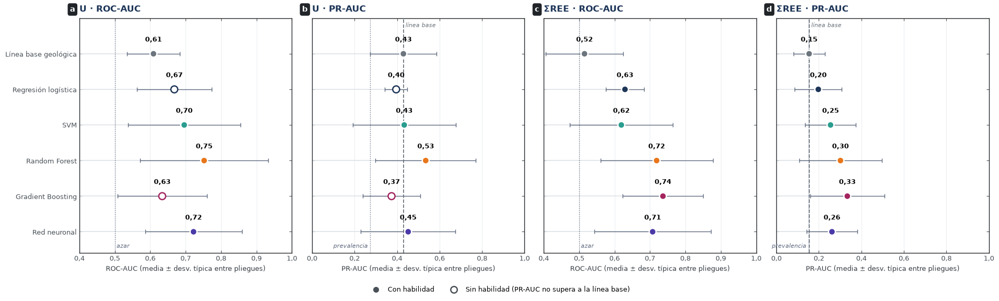

In [15]:
'''Figura 4: desempeño de los cinco modelos y de la línea base'''

COLOR_MODELO = {modelo.LINEA_BASE: '#6c757d', 'Regresión logística': '#1d3557', 'SVM': '#2a9d8f',
                'Random Forest': '#e8761a', 'Gradient Boosting': '#a3245e', 'Red neuronal': '#4a3aa7'}
fig, ejes = plt.subplots(1, 4, figsize=(19, 5.2), sharey=True, layout='constrained')
for i, (etiqueta, nombre) in enumerate(modelo.ETIQUETAS.items()):
    tab = METRICAS[etiqueta].loc[list(COLOR_MODELO)]
    for j, metrica in enumerate(['ROC-AUC', 'PR-AUC']):
        ax = ejes[2 * i + j]
        x, err = tab[metrica], tab[f'{metrica} desv.']
        inicio = 0.4 if metrica == 'ROC-AUC' else 0.0
        ax.hlines(range(len(tab)), inicio, x, color='#dee2e6', lw=1.2)
        ax.errorbar(x, range(len(tab)), xerr=err, fmt='none', ecolor=graf.COLOR_REF, capsize=3, lw=1)
        # Relleno blanco: modelo sin habilidad en esta etiqueta (PR-AUC no supera a la línea base)
        con_habilidad = [m in HABILES[etiqueta] or m == modelo.LINEA_BASE for m in tab.index]
        colores = list(COLOR_MODELO.values())
        ax.scatter(x, range(len(tab)), s=90, c=[c if h else 'white' for c, h in zip(colores, con_habilidad)],
                   edgecolor=[('white' if h else c) for c, h in zip(colores, con_habilidad)], lw=1.8, zorder=3)
        for k, v in enumerate(x):
            ax.text(v, k - 0.3, graf.numero_es(v, 2), ha='center', va='bottom', fontsize=9, fontweight='bold')
        if metrica == 'ROC-AUC':
            ax.axvline(0.5, color=graf.COLOR_REF, ls=':', lw=1)
            ax.text(0.505, len(tab) - 0.55, 'azar', fontsize=8, style='italic', color=graf.COLOR_REF)
        else:
            base = tab.loc[modelo.LINEA_BASE, 'PR-AUC']
            ax.axvline(base, color='#6c757d', ls='--', lw=1.3)
            ax.text(base + 0.01, -0.75, 'línea base', fontsize=8, style='italic', color='#6c757d')
            ax.axvline(tab.prevalencia.iloc[0], color=graf.COLOR_REF, ls=':', lw=1)
            ax.text(tab.prevalencia.iloc[0] - 0.01, len(tab) - 0.55, 'prevalencia', fontsize=8, style='italic',
                    color=graf.COLOR_REF, ha='right')
        if i == 0 and j == 0:
            ax.set_yticks(range(len(tab)), tab.index)
        ax.set_ylim(len(tab) - 0.4, -1.0)
        ax.set_xlim(inicio, 1.0)
        ax.set_xlabel(f'{metrica} (media ± desv. típica entre pliegues)', fontsize=9)
        ax.set_title(f'{nombre} · {metrica}')
        graf.ejes_coma_decimal(ax, y=False, d=1)
        ax.grid(axis='y', visible=False)
        graf.letra(ax, 'abcd'[2 * i + j])
fig.legend(handles=[Line2D([], [], marker='o', ls='', mfc=graf.GRIS, mec='white', ms=9, label='Con habilidad'),
                    Line2D([], [], marker='o', ls='', mfc='white', mec=graf.GRIS, mew=1.8, ms=9,
                           label='Sin habilidad (PR-AUC no supera a la línea base)')],
           loc='lower center', bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
graf.guardar(fig, 'GC04_04_validacion_anidada.png', svg=True)

**Lectura:** para **U**, tres de los cinco modelos superan a la línea base geológica (PR-AUC de 0,43): el Random
Forest (ROC-AUC de 0,75 y PR-AUC de 0,54), la red neuronal (0,72 y 0,45) y la SVM (0,70 y 0,43, apenas por encima). La
regresión logística y el Gradient Boosting no la superan. Para **ΣREE**, los cinco modelos superan a la línea base,
que aquí es casi el azar (ROC-AUC de 0,52 y PR-AUC de 0,15, igual a la prevalencia): el mejor es el Gradient Boosting
(0,74 y 0,33), seguido del Random Forest (0,72 y 0,30). La geología del mapa explica parte del U, porque el U positivo
se concentra en un plutón, pero casi nada de las REE.

Las desviaciones entre pliegues son grandes (0,16 a 0,24 en la PR-AUC) y los hiperparámetros elegidos cambian de un
pliegue a otro. Las dos cosas indican que, con 60 a 117 positivos agrupados en pocos sectores, el desempeño depende de
qué sector se evalúa. Los valores medios son una estimación razonable, pero con una incertidumbre amplia.

***

<a id="parte-7"></a>

## <span style="color:#e8761a">**7. QUÉ VARIABLES USAN LOS MODELOS**</span>
***

La **importancia por permutación** desordena una variable en las rocas de evaluación de cada pliegue y mide cuánto cae
la PR-AUC. Se calcula con los modelos de la validación anidada, así que no requiere reentrenar. Si algoritmos distintos
dependen de las mismas variables, es más probable que la relación sea geológica y no un efecto del algoritmo.

In [16]:
'''Importancia por permutación de cada modelo, promediada en los pliegues externos'''
IMPORTANCIA = {}
for etiqueta in modelo.ETIQUETAS:
    d, y, pl, _, ajustados, _ = VALIDACION[etiqueta]
    IMPORTANCIA[etiqueta] = pd.DataFrame({m: modelo.importancia(ajustados, d, y, pl, VARS[etiqueta], m)
                                          for m in COLOR_MODELO if m != modelo.LINEA_BASE})
    imp = IMPORTANCIA[etiqueta][HABILES[etiqueta]]
    rho = imp.corr(method='spearman').values[np.triu_indices(len(imp.columns), 1)]
    print(f'{modelo.ETIQUETAS[etiqueta]}: correlación media de las importancias entre modelos hábiles = '
          f'{rho.mean():.2f}')
pd.concat({modelo.ETIQUETAS[e]: i.mean(axis=1).sort_values(ascending=False).head(6) for e, i in IMPORTANCIA.items()},
          axis=1)

U: correlación media de las importancias entre modelos hábiles = 0.22


ΣREE: correlación media de las importancias entre modelos hábiles = 0.10


,U,ΣREE
sed_Be,0.067,NaN
grav_XGM2019e,0.021,0.009
sed_Y,0.011,NaN
sed_La_Y,0.010,NaN
dist_PT_km,0.005,NaN
dist_san_ramon_km,0.005,NaN
cue_La,NaN,0.022
dist_falla_regional_km,NaN,0.022
cue_Y,NaN,0.020
litologia_felsica,NaN,0.013


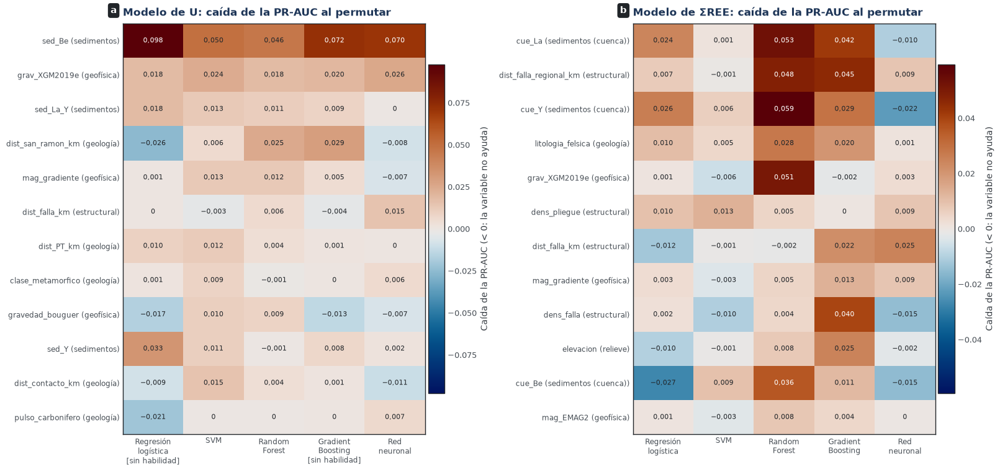

In [17]:
'''Figura 5: importancia de las 12 variables principales en cada modelo'''

fig, ejes = plt.subplots(1, 2, figsize=(16, 7.5), layout='constrained')
for ax, (etiqueta, nombre), letra in zip(ejes, modelo.ETIQUETAS.items(), 'ab'):
    imp = IMPORTANCIA[etiqueta]
    top = imp[HABILES[etiqueta]].mean(axis=1).sort_values(ascending=False).head(12).index
    datos = imp.loc[top]
    lim = np.abs(datos.values).max()
    im = ax.imshow(datos.values, cmap=graf.CMAP_DIVERGENTE, vmin=-lim, vmax=lim, aspect='auto')
    for (i, j), v in np.ndenumerate(datos.values):
        ax.text(j, i, '0' if abs(v) < 5e-4 else graf.numero_es(v, 3).replace('-', '−'), ha='center', va='center',
                fontsize=8, color='white' if abs(v) > 0.6 * lim else '#212529')
    ax.set_yticks(range(len(top)), [f'{v} ({familia[v].lower()})' for v in top], fontsize=8.5)
    ax.set_xticks(range(len(datos.columns)), [m.replace(' ', '\n', 1) + ('' if m in HABILES[etiqueta] else
                                                                         '\n[sin habilidad]')
                                              for m in datos.columns], fontsize=8.5)
    ax.tick_params(top=False, right=False, bottom=False, left=False)
    ax.grid(False)
    ax.set_title(f'Modelo de {nombre}: caída de la PR-AUC al permutar')
    graf.letra(ax, letra)
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.01, label='Caída de la PR-AUC (< 0: la variable no ayuda)')
graf.guardar(fig, 'GC04_05_importancia_variables.png', svg=True)

La importancia dice cuánto pesa una variable, pero no en qué dirección. La **dependencia parcial** lo muestra: es la
probabilidad media que da el modelo cuando todas las rocas toman un mismo valor de la variable. Se calcula con los
modelos finales, ajustados con todas las rocas de entrenamiento (sección 8), para las dos variables principales del U.

***

<a id="parte-8"></a>

## <span style="color:#e8761a">**8. MAPAS DE FAVORABILIDAD Y CONSENSO**</span>
***

Cada modelo final se ajusta con todas las rocas de entrenamiento, con la misma búsqueda interna de hiperparámetros, y
se aplica a las 246 400 celdas de la grilla. Las probabilidades de algoritmos distintos no son comparables y, por
entrenarse con clases equilibradas, no están calibradas. Por eso cada mapa se convierte a **percentil de
favorabilidad** dentro del área (0 a 100), que solo depende del orden de las celdas.

Las **clases** se definen por área: **A** es el 5 % más favorable, **B** el 5 a 15 % y **C** el 15 a 30 %. El
**consenso** cuenta cuántos modelos con habilidad ubican cada celda en la clase A; una celda donde coinciden todos
tiene más prioridad que una señalada por un solo modelo.

In [18]:
'''Modelos finales, mapas en percentiles, consenso y clase de la mediana (unos dos minutos)'''
FINALES, PERCENTIL, PRODUCTO = {}, {}, {}
perfil = modelo.leer_variable('elevacion')[1]
FORMA = (perfil['height'], perfil['width'])
EXTENSION = modelo.extension(perfil)
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y = modelo.conjunto(tabla, etiqueta)
    matriz = modelo.pila(VARS[etiqueta])
    for m in COLOR_MODELO:
        if m == modelo.LINEA_BASE:
            continue
        FINALES[(etiqueta, m)], _ = modelo.ajustar(m, d, y, VARS[etiqueta], modelo.bloques(d))
        PERCENTIL[(etiqueta, m)] = modelo.a_percentil(modelo.predecir(FINALES[(etiqueta, m)], matriz)).reshape(FORMA)
    del matriz
    hab = [PERCENTIL[(etiqueta, m)] for m in HABILES[etiqueta]]
    mediana = np.nanmedian(np.stack(hab), axis=0)
    PRODUCTO[etiqueta] = {'mediana': mediana, 'consenso': modelo.consenso(hab), 'clase': modelo.clase(mediana)}
    corto = nombre.replace('Σ', 'S')
    for clave, matriz_salida in PRODUCTO[etiqueta].items():
        modelo.guardar_tif(RESULTADOS / f'{corto}_{clave}.tif', matriz_salida, perfil)

'''Áreas de las clases y del consenso, y parecido entre los mapas de los modelos'''
filas = []
for etiqueta, nombre in modelo.ETIQUETAS.items():
    n, c, cl = len(HABILES[etiqueta]), PRODUCTO[etiqueta]['consenso'], PRODUCTO[etiqueta]['clase']
    pcs = pd.DataFrame({m: PERCENTIL[(etiqueta, m)].ravel()[celdas] for m in HABILES[etiqueta]})
    filas.append({'etiqueta': nombre, 'modelos hábiles': n,
                  'ρ media entre mapas': pcs.corr(method='spearman').values[np.triu_indices(n, 1)].mean(),
                  'clase A (km²)': modelo.CELDA_KM2 * (cl == 3).sum(),
                  'clase B (km²)': modelo.CELDA_KM2 * (cl == 2).sum(),
                  f'A en todos los hábiles (km²)': modelo.CELDA_KM2 * (c == n).sum(),
                  f'A en todos menos uno (km²)': modelo.CELDA_KM2 * (c >= n - 1).sum()})
pd.DataFrame(filas).set_index('etiqueta')

,modelos hábiles,ρ media entre mapas,clase A (km²),clase B (km²),A en todos los hábiles (km²),A en todos menos uno (km²)
etiqueta,,,,,,
U,3,0.510,614.750,1504.000,321.688,614.75
ΣREE,5,0.655,548.188,1639.812,101.938,268.25


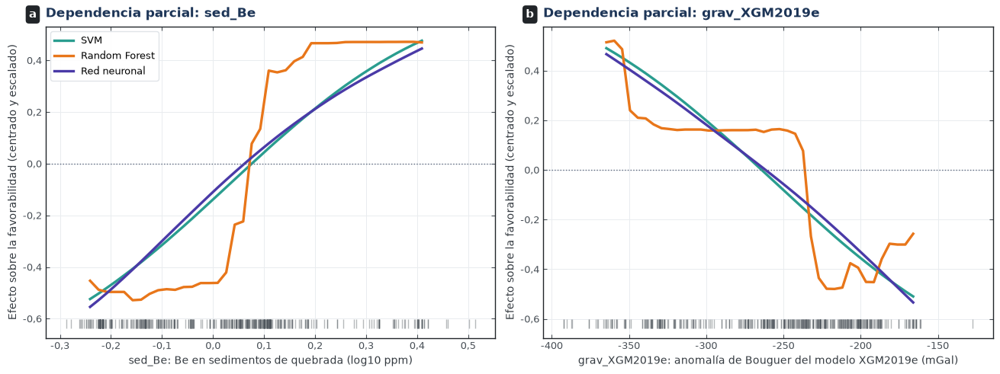

In [19]:
'''Figura 6: dependencia parcial de las dos variables más importantes del U en los modelos hábiles'''

d, y = modelo.conjunto(tabla, 'U_pos')
principales = IMPORTANCIA['U_pos'][HABILES['U_pos']].mean(axis=1).sort_values(ascending=False).index[:2]
ROTULO_PD = {'sed_Be': 'sed_Be: Be en sedimentos de quebrada (log10 ppm)',
             'grav_XGM2019e': 'grav_XGM2019e: anomalía de Bouguer del modelo XGM2019e (mGal)'}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8), layout='constrained')
for ax, variable, letra in zip(ejes, principales, 'ab'):
    i = VARS['U_pos'].index(variable)
    x_rocas = d[VARS['U_pos']].values
    x_rocas = x_rocas[np.isfinite(x_rocas[:, i])]
    for m in HABILES['U_pos']:
        pd_ = partial_dependence(FINALES[('U_pos', m)], x_rocas, [i], grid_resolution=40,
                                 percentiles=(0.03, 0.97), kind='average')
        valores, curva = pd_['grid_values'][0], pd_['average'][0]
        ax.plot(valores, (curva - curva.mean()) / (curva.max() - curva.min() + 1e-9), lw=2.4,
                color=COLOR_MODELO[m], label=m)
    ax.plot(d[variable], np.full(len(d), -0.62), '|', color=graf.GRIS, alpha=0.4, ms=9)
    ax.axhline(0, color=graf.COLOR_REF, ls=':', lw=1)
    ax.set_xlabel(ROTULO_PD.get(variable, variable))
    ax.set_ylabel('Efecto sobre la favorabilidad (centrado y escalado)')
    ax.set_title(f'Dependencia parcial: {variable}')
    graf.ejes_coma_decimal(ax, y=False, d=1 if np.ptp(valores) < 10 else 0)
    graf.ejes_coma_decimal(ax, x=False, d=1)
    graf.letra(ax, letra)
ejes[0].legend(loc='upper left')
graf.guardar(fig, 'GC04_06_dependencia_parcial.png', svg=True)

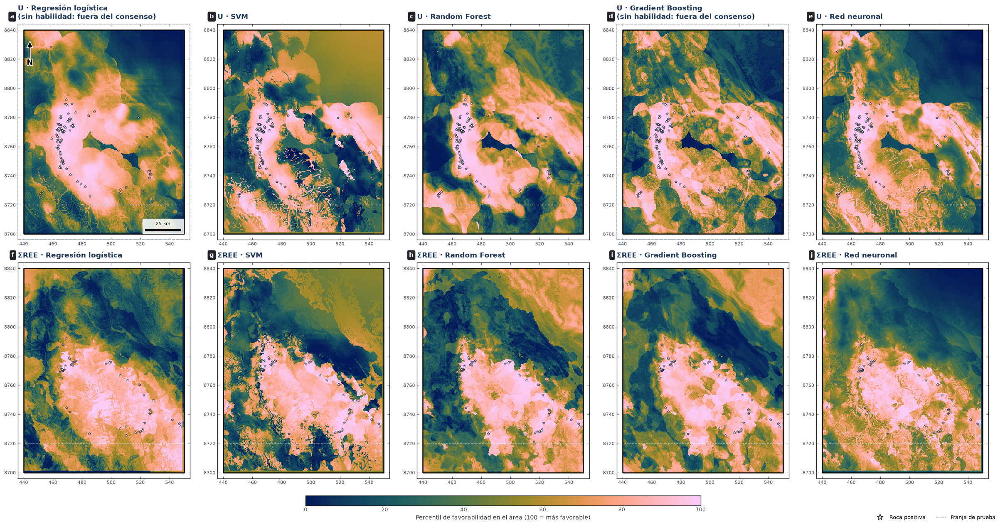

In [20]:
'''Figura 7: percentil de favorabilidad de los cinco modelos (U arriba, ΣREE abajo)'''

fig, ejes = plt.subplots(2, 5, figsize=(24, 12.5), layout='constrained')
for fila, (etiqueta, nombre) in enumerate(modelo.ETIQUETAS.items()):
    d, y = modelo.conjunto(tabla, etiqueta)
    for col, m in enumerate([m for m in COLOR_MODELO if m != modelo.LINEA_BASE]):
        ax = ejes[fila, col]
        im = ax.imshow(PERCENTIL[(etiqueta, m)], extent=EXTENSION, cmap='cmc.batlow', vmin=0, vmax=100,
                       interpolation='nearest')
        franja.boundary.plot(ax=ax, color='white', lw=0.9, ls='--')
        ax.scatter(d.x[y == 1], d.y[y == 1], s=22, marker='*', color='white', edgecolor='#212529', lw=0.5, zorder=5)
        habil = m in HABILES[etiqueta]
        graf.marco_mapa(ax, aoi, f'{nombre} · {m}' + ('' if habil else '\n(sin habilidad: fuera del consenso)'),
                        accesorios=(fila == 0 and col == 0))
        if not habil:
            for borde in ax.spines.values():
                borde.set(color='#adb5bd', linestyle='--', linewidth=1.4)
        ax.grid(False)
        ax.set_xlabel('')
        ax.set_ylabel('')
        graf.letra(ax, 'abcdefghij'[fila * 5 + col])
barra = fig.colorbar(im, ax=ejes, orientation='horizontal', shrink=0.4, pad=0.02, aspect=40)
barra.set_label('Percentil de favorabilidad en el área (100 = más favorable)')
fig.legend(handles=[Line2D([], [], marker='*', ls='', mfc='white', mec='#212529', ms=11, label='Roca positiva'),
                    Line2D([], [], color='#adb5bd', ls='--', label='Franja de prueba')],
           loc='lower right', ncol=2, frameon=False)
graf.guardar(fig, 'GC04_07_mapas_cinco_modelos.png')

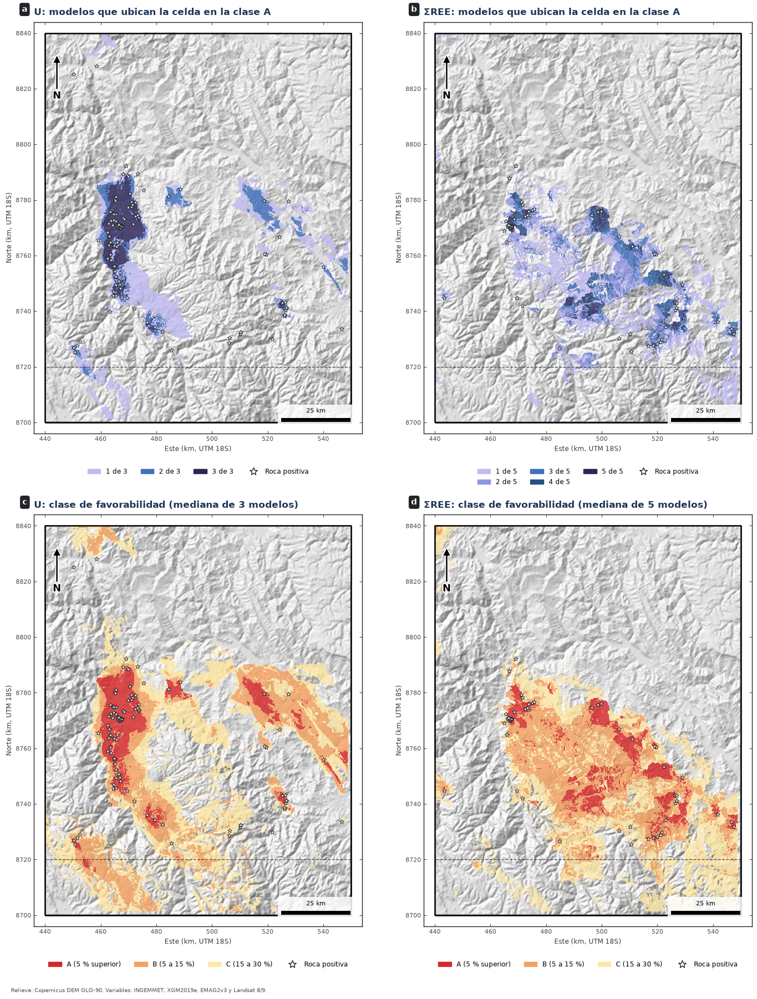

In [21]:
'''Figura 8: acuerdo entre modelos hábiles en la clase A y clase de favorabilidad de la mediana, sobre el relieve'''

COLOR_CLASE = {3: '#d62828', 2: '#f4a261', 1: '#ffe8a3'}
fig, ejes = plt.subplots(2, 2, figsize=(14, 17.5), layout='constrained')
for col, (etiqueta, nombre) in enumerate(modelo.ETIQUETAS.items()):
    d, y = modelo.conjunto(tabla, etiqueta)
    n = len(HABILES[etiqueta])
    rampa = plt.get_cmap('cmc.devon_r')(np.linspace(0.3, 0.95, n))
    for fila in range(2):
        ax = ejes[fila, col]
        graf.relieve(ax, elevacion, ext_relieve, opacidad=0.75)
        if fila == 0:
            matriz, colores = PRODUCTO[etiqueta]['consenso'], {k: rampa[k - 1] for k in range(1, n + 1)}
            titulo_mapa = f'{nombre}: modelos que ubican la celda en la clase A'
            leyenda = [Patch(color=colores[k], label=f'{k} de {n}') for k in range(1, n + 1)]
        else:
            matriz, colores = PRODUCTO[etiqueta]['clase'], COLOR_CLASE
            titulo_mapa = f'{nombre}: clase de favorabilidad (mediana de {n} modelos)'
            leyenda = [Patch(color=COLOR_CLASE[k], label=f'{modelo.CLASES[k]} ({t})')
                       for k, t in [(3, '5 % superior'), (2, '5 a 15 %'), (1, '15 a 30 %')]]
        rgba = np.zeros(matriz.shape + (4,))
        for k, c in colores.items():
            rgba[matriz == k] = [*to_rgb(c), 0.82]
        ax.imshow(rgba, extent=EXTENSION, interpolation='nearest', zorder=2)
        franja.boundary.plot(ax=ax, color='#495057', lw=1, ls='--', zorder=3)
        ax.scatter(d.x[y == 1], d.y[y == 1], s=34, marker='*', color='white', edgecolor='#212529', lw=0.6, zorder=5)
        graf.marco_mapa(ax, aoi, titulo_mapa)
        ax.grid(False)
        ax.legend(handles=leyenda + [Line2D([], [], marker='*', ls='', mfc='white', mec='#212529', ms=10,
                                            label='Roca positiva')],
                  loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=4, fontsize=8.5, frameon=False)
        graf.letra(ax, 'abcd'[fila * 2 + col])
graf.fuente_figura(fig, 'Relieve: Copernicus DEM GLO-90. Variables: INGEMMET, XGM2019e, EMAG2v3 y Landsat 8/9.')
graf.guardar(fig, 'GC04_08_consenso_y_clases.png')

**Lectura:** el Be de los sedimentos es la variable más importante del U en los cinco modelos (caída de la PR-AUC de
0,05 a 0,10), seguida de la anomalía de Bouguer de XGM2019e, que aparece en segundo lugar también en los cinco. Más
allá de esas dos, los modelos no coinciden (correlación media de las importancias de 0,22). En ΣREE dominan el La y el
Y por cuenca y la distancia a las fallas regionales, con menos acuerdo entre modelos (0,10). La dependencia parcial
(figura 6) muestra que los tres modelos hábiles del U responden igual: la favorabilidad sube con el Be, con un salto en
el Random Forest entre 1,1 y 1,3 ppm de Be, y sube donde la anomalía de Bouguer es más negativa.

En los mapas (figuras 7 y 8), los modelos de U coinciden en el Sienogranito San Ramón y su borde sur (305 km² con los
tres modelos en la clase A, entre La Merced y el sur de San Ramón) y en dos sectores pequeños, al sur (480 E, 8735 N) y
al sureste (525 E, 8742 N). Las clases A y B de la mediana marcan además un cinturón al noreste, entre 515 y 545 km E,
donde solo uno o dos modelos llegan a la clase A: es un sector a verificar. Para ΣREE, los cinco modelos coinciden en
102 km² repartidos en varios núcleos: el borde norte de San Ramón, cerca de La Merced, y sectores al este y sureste
(490 a 530 km E). Los mapas de U de los tres modelos hábiles se parecen moderadamente (ρ = 0,51) y los de ΣREE algo
más (0,66).

***

<a id="parte-9"></a>

## <span style="color:#e8761a">**9. FRANJA DE PRUEBA Y PRUEBA CONTRA EL AZAR ESPACIAL**</span>
***

Se aplican dos pruebas adicionales:

1. **Franja de prueba.** Se evalúa una sola vez la franja sur, que tiene otra geología y que ninguna decisión anterior
   usó. Mide si el modelo extrapola. Cada roca recibe el percentil de la celda donde cae en cada mapa y la mediana de
   los modelos hábiles.
2. **Azar espacial.** Las rocas positivas están agrupadas, sobre todo en el Sienogranito San Ramón, y cualquier
   variable con un patrón espacial parecido podría separarlas. Se desplaza el campo de etiquetas un vector al azar,
   con retorno por los bordes (traslación toroidal; Fortin y Dale, 2005), y se repite la validación con el Random
   Forest. Si el modelo real no supera con claridad a esas réplicas, su ventaja puede deberse a la estructura espacial
   y no a una relación geológica.

In [22]:
'''Prueba 1: franja de prueba (evaluación única)'''
def percentil_en(matriz, puntos):
    col = ((puntos.x - EXTENSION[0]) / 250).astype(int).clip(0, FORMA[1] - 1)
    fila = ((EXTENSION[3] - puntos.y) / 250).astype(int).clip(0, FORMA[0] - 1)
    return matriz[fila, col]

filas = []
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y = modelo.conjunto(tabla, etiqueta)
    dp, yp = modelo.conjunto(tabla, etiqueta, 'prueba')
    puntajes = {modelo.LINEA_BASE: modelo.linea_base(d, y, dp),
                **{m: percentil_en(PERCENTIL[(etiqueta, m)], dp) for m in HABILES[etiqueta]},
                'Mediana de los hábiles': percentil_en(PRODUCTO[etiqueta]['mediana'], dp)}
    for m, p in puntajes.items():
        evaluable = 0 < yp.sum() < len(yp) and yp.sum() >= 5
        filas.append({'etiqueta': nombre, 'modelo': m, 'rocas': len(dp), 'positivas': int(yp.sum()),
                      'ROC-AUC': roc_auc_score(yp, p, sample_weight=dp.peso) if evaluable else np.nan,
                      'PR-AUC': average_precision_score(yp, p, sample_weight=dp.peso) if evaluable else np.nan,
                      'prevalencia': np.average(yp, weights=dp.peso)})
prueba = pd.DataFrame(filas).set_index(['etiqueta', 'modelo'])
prueba

rocas  positivas  ROC-AUC  PR-AUC  \
etiqueta modelo                                                      
U        Línea base geológica      107         16    0.625   0.204   
         SVM                       107         16    0.642   0.267   
         Random Forest             107         16    0.663   0.323   
         Red neuronal              107         16    0.722   0.258   
         Mediana de los hábiles    107         16    0.701   0.330   
ΣREE     Línea base geológica       88          4      NaN     NaN   
         Regresión logística        88          4      NaN     NaN   
         SVM                        88          4      NaN     NaN   
         Random Forest              88          4      NaN     NaN   
         Gradient Boosting          88          4      NaN     NaN   
         Red neuronal               88          4      NaN     NaN   
         Mediana de los hábiles     88          4      NaN     NaN   

                                 prevalencia  
etiqueta modelo                               
U        Línea base geológica          0.152  
         SVM                           0.152  
         Random Forest                 0.152  
         Red neuronal                  0.152  
         Mediana de los hábiles        0.152  
ΣREE     Línea base geológica          0.041  
         Regresión logística           0.041  
         SVM                           0.041  
         Random Forest                 0.041  
         Gradient Boosting             0.041  
         Red neuronal                  0.041  
         Mediana de los hábiles        0.041

In [23]:
'''Prueba 2: traslación toroidal de las etiquetas (99 réplicas por etiqueta; unos cuatro minutos)'''
N_AZAR = 99
rng = np.random.default_rng(modelo.SEMILLA)
AZAR, filas = {}, []
for etiqueta, nombre in modelo.ETIQUETAS.items():
    d, y, pl, *_ = VALIDACION[etiqueta]
    params = {k: v for k, v in FINALES[(etiqueta, 'Random Forest')].get_params().items()
              if k in ('min_samples_leaf', 'max_features')}
    observado = modelo.mejora_sobre_base(d, y, pl, VARS[etiqueta], params)
    nulos = pd.DataFrame([modelo.mejora_sobre_base(d, modelo.trasladar_etiquetas(d, y, rng), pl, VARS[etiqueta],
                                                   params) for _ in range(N_AZAR)]).dropna()
    AZAR[etiqueta] = (observado, nulos)
    for metrica in ['ROC-AUC', 'mejora PR-AUC']:
        filas.append({'etiqueta': nombre, 'métrica': metrica, 'modelo real': observado[metrica],
                      'mediana del azar': nulos[metrica].median(), 'percentil 95 del azar': nulos[metrica].quantile(0.95),
                      'réplicas válidas': len(nulos), 'valor p': modelo.valor_p(observado[metrica], nulos[metrica])})
pd.DataFrame(filas).set_index(['etiqueta', 'métrica'])

modelo real  mediana del azar  percentil 95 del azar  \
etiqueta métrica                                                               
U        ROC-AUC              0.762             0.556                  0.794   
         mejora PR-AUC        0.119             0.068                  0.285   
ΣREE     ROC-AUC              0.741             0.575                  0.874   
         mejora PR-AUC        0.156             0.025                  0.362   

                        réplicas válidas  valor p  
etiqueta métrica                                   
U        ROC-AUC                      99    0.100  
         mejora PR-AUC                99    0.360  
ΣREE     ROC-AUC                      96    0.175  
         mejora PR-AUC                96    0.165

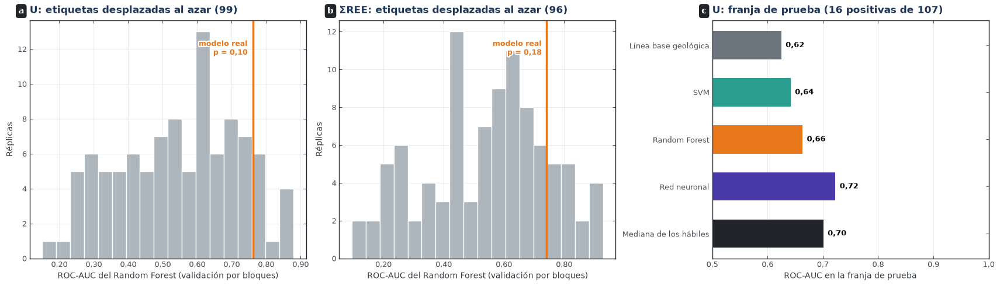

In [24]:
'''Figura 9: (a, b) distribución del azar espacial frente al modelo real y (c) franja de prueba'''

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8), layout='constrained')
for ax, (etiqueta, nombre), letra in zip(ejes[:2], modelo.ETIQUETAS.items(), 'ab'):
    observado, nulos = AZAR[etiqueta]
    ax.hist(nulos['ROC-AUC'], bins=18, color='#adb5bd', edgecolor='white')
    ax.axvline(observado['ROC-AUC'], color='#e8761a', lw=2.5)
    p = modelo.valor_p(observado['ROC-AUC'], nulos['ROC-AUC'])
    ax.text(observado['ROC-AUC'] - 0.01, ax.get_ylim()[1] * 0.92, f'modelo real\np = {graf.numero_es(p, 2)}',
            color='#e8761a', fontsize=9, fontweight='bold', va='top', ha='right', path_effects=graf.HALO)
    ax.set_xlabel('ROC-AUC del Random Forest (validación por bloques)')
    ax.set_ylabel('Réplicas')
    ax.set_title(f'{nombre}: etiquetas desplazadas al azar ({len(nulos)})')
    graf.ejes_coma_decimal(ax, y=False, d=2)
    graf.letra(ax, letra)
ax = ejes[2]
tab = prueba.loc['U'].dropna(subset=['ROC-AUC'])
colores = [COLOR_MODELO.get(m, '#212529') for m in tab.index]
ax.barh(range(len(tab)), tab['ROC-AUC'] - 0.5, left=0.5, color=colores, height=0.6)
for k, v in enumerate(tab['ROC-AUC']):
    ax.text(v + 0.008, k, graf.numero_es(v, 2), va='center', fontsize=9, fontweight='bold')
ax.set_yticks(range(len(tab)), tab.index)
ax.invert_yaxis()
ax.set_xlim(0.5, 1)
ax.set_xlabel('ROC-AUC en la franja de prueba')
ax.set_title(f'U: franja de prueba ({int(tab.positivas.iloc[0])} positivas de {int(tab.rocas.iloc[0])})')
graf.ejes_coma_decimal(ax, y=False, d=1)
ax.grid(axis='y', visible=False)
graf.letra(ax, 'c')
graf.guardar(fig, 'GC04_09_pruebas_exigentes.png', svg=True)

**Lectura:** en la franja de prueba, la mediana de los modelos hábiles de U supera a la línea base geológica (ROC-AUC
de 0,70 frente a 0,63 y PR-AUC de 0,33 frente a 0,20, con una prevalencia de 0,15). La red neuronal es la que mejor
extrapola en ROC-AUC (0,72) y el Random Forest en PR-AUC (0,32). La ventaja sobre la línea base es menor que en la
validación cruzada. En ΣREE la franja tiene solo 4 rocas positivas y no permite una evaluación.

En la prueba contra el azar espacial, el Random Forest de U alcanza un ROC-AUC de 0,76, cuando la
mediana de las etiquetas desplazadas es 0,56, pero 9 de las 99 réplicas igualan o superan ese valor (p = 0,10); en
ΣREE, p = 0,18. Con positivos tan agrupados, una parte del desempeño se puede obtener con cualquier variable que tenga
un patrón espacial parecido. Ninguno de los dos resultados es significativo al 5 %. Por eso los mapas sirven para
decidir dónde muestrear primero, pero no prueban que exista mineralización.

***

<a id="parte-10"></a>

## <span style="color:#e8761a">**10. ZONAS PRIORITARIAS PARA U Y ΣREE**</span>
***

Se cruzan las clases de favorabilidad de U y de ΣREE. Como el U y las REE responden a variables en parte distintas
(secciones 7 y 8), las celdas favorables para los dos son pocas. Se distinguen cuatro categorías y, dentro de la de
mayor prioridad, el **blanco estable**: las celdas donde todos los modelos hábiles de U y todos los de ΣREE coinciden
en la clase A.

In [25]:
'''Cruce de clases: 4 = A en las dos, 3 = A en una y B en la otra, 2 = solo U, 1 = solo ΣREE (clase A o B)'''
cu, cr = PRODUCTO['U_pos']['clase'], PRODUCTO['SREE_pos']['clase']
au, ar = cu >= 3, cr >= 3
bu, br = cu >= 2, cr >= 2
cruce = np.select([au & ar, (au & br) | (bu & ar), bu & ~br, br & ~bu], [4, 3, 2, 1], 0).astype(float)
cruce[~np.isfinite(cu) | ~np.isfinite(cr)] = np.nan
estable = ((PRODUCTO['U_pos']['consenso'] == len(HABILES['U_pos'])) &
           (PRODUCTO['SREE_pos']['consenso'] == len(HABILES['SREE_pos'])))
modelo.guardar_tif(RESULTADOS / 'cruce_U_SREE.tif', cruce, perfil)
modelo.guardar_tif(RESULTADOS / 'blanco_estable_U_SREE.tif', np.where(np.isfinite(cruce), estable, np.nan), perfil)

NOMBRE_CRUCE = {4: 'Uranio y tierras raras (A y A)', 3: 'Una en A y la otra en B', 2: 'Solo uranio (A o B)',
                1: 'Solo tierras raras (A o B)'}
areas = pd.Series({NOMBRE_CRUCE[k]: modelo.CELDA_KM2 * (cruce == k).sum() for k in NOMBRE_CRUCE}, name='km²')
areas['Blanco estable (todos los modelos, A y A)'] = modelo.CELDA_KM2 * estable.sum()
ok = np.isfinite(PRODUCTO['U_pos']['mediana'].ravel()[celdas]) & np.isfinite(PRODUCTO['SREE_pos']['mediana'].ravel()[celdas])
print(f"ρ entre los percentiles de U y de ΣREE: "
      f"{stats.spearmanr(PRODUCTO['U_pos']['mediana'].ravel()[celdas][ok], PRODUCTO['SREE_pos']['mediana'].ravel()[celdas][ok])[0]:.2f}")
areas.to_frame().assign(**{'% del área': lambda t: 100 * t['km²'] / (modelo.CELDA_KM2 * np.isfinite(cruce).sum())})

ρ entre los percentiles de U y de ΣREE: 0.07


,km²,% del área
Uranio y tierras raras (A y A),73.250,0.476
Una en A y la otra en B,126.250,0.820
Solo uranio (A o B),1728.000,11.221
Solo tierras raras (A o B),1797.250,11.670
"Blanco estable (todos los modelos, A y A)",16.375,0.106


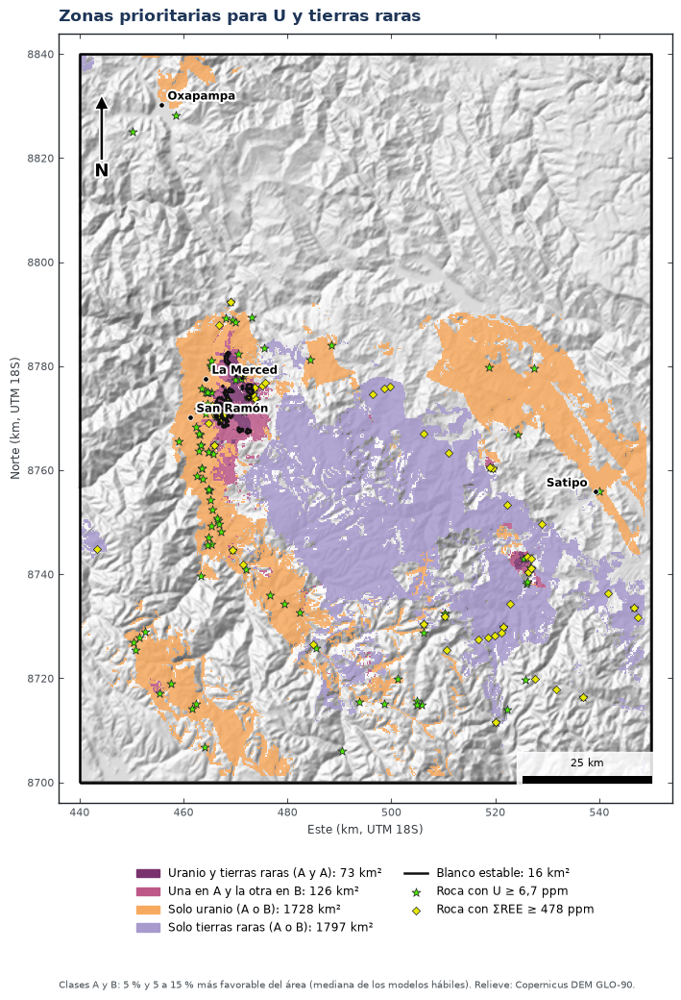

Tiempo total del cuaderno: 14.3 min


In [26]:
'''Figura 10: producto final, zonas prioritarias para U y ΣREE sobre el relieve'''

COLOR_CRUCE = {4: '#79326e', 3: '#bd5888', 2: '#f7aa5f', 1: '#a79acd'}
capitales = lectura.cargar_capa('capitales')
capitales = capitales[capitales.within(aoi.union_all()) &
                      (capitales.NOMTIPO.eq('CAPITAL PROVINCIAL') | capitales.NOMPOB.eq('SAN RAMON'))].copy()
capitales['nombre'] = capitales.NOMPOB.str.title().str.replace('Ramon', 'Ramón')
fig, ax = plt.subplots(figsize=(8.6, 10.4))
graf.relieve(ax, elevacion, ext_relieve, opacidad=0.8)
rgba = np.zeros(cruce.shape + (4,))
for k, c in COLOR_CRUCE.items():
    rgba[cruce == k] = [*to_rgb(c), 0.85]
ax.imshow(rgba, extent=EXTENSION, interpolation='nearest', zorder=2)
ax.contour(np.where(estable, 1.0, 0.0), levels=[0.5], extent=(EXTENSION[0], EXTENSION[1], EXTENSION[3], EXTENSION[2]),
           colors='#111111', linewidths=1.8, zorder=7)
for et, marca, color, rotulo in [('U_pos', '*', '#4ce600', 'Roca con U ≥ 6,7 ppm'),
                                 ('SREE_pos', 'D', '#e6e600', 'Roca con ΣREE ≥ 478 ppm')]:
    pos = tabla[tabla[et] == 1]
    ax.scatter(pos.x, pos.y, s=46 if marca == '*' else 18, marker=marca, color=color, edgecolor='#212529', lw=0.5,
               zorder=6, label=rotulo)
graf.rotular_lugares(ax, capitales, 'nombre', aoi, tamano=8.5, marcador=16)
graf.marco_mapa(ax, aoi, 'Zonas prioritarias para U y tierras raras')
ax.grid(False)
h, l = ax.get_legend_handles_labels()
h = [Patch(color=COLOR_CRUCE[k], label=f'{NOMBRE_CRUCE[k]}: {graf.numero_es(areas[NOMBRE_CRUCE[k]], 0)} km²')
     for k in COLOR_CRUCE] + [Line2D([], [], color='#111111', lw=1.8,
                                    label=f'Blanco estable: {graf.numero_es(areas.iloc[-1], 0)} km²')] + h
ax.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, -0.07), ncol=2, fontsize=8.5, frameon=False)
graf.fuente_al_pie(ax, 'Clases A y B: 5 % y 5 a 15 % más favorable del área (mediana de los modelos hábiles). '
                   'Relieve: Copernicus DEM GLO-90.', y=-0.23)
graf.guardar(fig, 'GC04_10_zonas_prioritarias.png')
print(f'Tiempo total del cuaderno: {(time.time() - INICIO) / 60:.1f} min')

**Lectura:** los percentiles de U y de ΣREE casi no se correlacionan en el área (ρ = 0,07): los dos modelos señalan
zonas distintas. Por eso las celdas con clase A en ambos ocupan solo 73 km² (0,5 % del área) y forman dos núcleos: el
principal, de 64 km², en el Sienogranito San Ramón al sur de La Merced, y otro de 6 km² al sureste (525 E, 8743 N). El
blanco estable, donde todos los modelos de U y todos los de ΣREE coinciden en la clase A, suma 16 km², casi todo en un
solo sector de 11 km² entre San Ramón y La Merced.

El área prioritaria queda en 16 a 73 km² de los 15 400 km² del área de estudio. El siguiente paso sería muestrear
rocas y sedimentos en ese sector, lo que permitiría además comprobar el modelo con datos nuevos.

***

<a id="parte-11"></a>

## <span style="color:#e8761a">**11. CONCLUSIONES**</span>
***

**Pregunta 4.** ¿Dónde es más favorable encontrar U y tierras raras con los datos públicos disponibles?

| Resultado | Valor | Interpretación |
|---|---|---|
| Integración | 40 variables en una grilla de 250 m; tres reconstruidas exactamente desde el repositorio | El flujo es reproducible |
| Mejor modelo de U (validación por bloques) | Random Forest: ROC-AUC 0,75 y PR-AUC 0,54 (línea base 0,61 y 0,43) | Supera al mapa geológico; 3 de 5 modelos tienen habilidad |
| Mejor modelo de ΣREE | Gradient Boosting: ROC-AUC 0,74 y PR-AUC 0,33 (línea base 0,52 y 0,15) | El mapa geológico casi no explica las REE; los 5 modelos tienen habilidad |
| Variables clave del U | Be de los sedimentos y anomalía de Bouguer de XGM2019e, en los cinco modelos | Granitos evolucionados y de baja densidad |
| Franja de prueba (U) | ROC-AUC 0,70 frente a 0,63 de la línea base | El modelo extrapola, con menos ventaja |
| Azar espacial | p = 0,10 (U) y 0,18 (ΣREE) | No significativo al 5 % |
| Zona prioritaria | 73 km² con clase A en U y ΣREE; blanco estable de 16 km² entre San Ramón y La Merced | Zona para una primera campaña de muestreo |

**Cómo se usaron GC02 y GC03:**
1. La validación de la gravedad justificó usar XGM2019e como variable regional y excluir la anomalía residual, que
   refleja el error de la reducción de Bouguer y el lugar de las estaciones.
2. La comparación de las fuentes de U llevó a fijar el umbral con un criterio geológico y a pesar cada afloramiento una
   sola vez.
3. El Be del sedimento, relacionado con el U en GC03, fue la variable más importante del U en los cinco modelos.

**Limitaciones:**
- No hay radiometría aérea pública, que sería la mejor variable para el U.
- Los positivos están muy agrupados (más de la mitad de los de U en San Ramón), lo que hace variar las métricas entre
  pliegues y explica el resultado de la prueba contra el azar espacial.
- Las probabilidades no están calibradas; los mapas se expresan en percentiles y clases por área.
- La franja de prueba no permite evaluar el modelo de ΣREE (4 positivas).
- La anomalía de Bouguer comparte el gradiente oeste-este con la elevación y con la densidad de muestreo, de modo que
  su papel debe confirmarse con datos de gravedad más densos.

***

<a id="ia"></a>

## <span style="color:#e8761a">**DECLARACIÓN DE USO DE INTELIGENCIA ARTIFICIAL**</span>
***

Se utilizó inteligencia artificial generativa como herramienta de apoyo en la programación y en la preparación de
textos y figuras. Los autores definieron el problema, las fuentes y los criterios del análisis, y revisaron y
validaron todos los resultados.

***

<a id="referencias"></a>

## <span style="color:#e8761a">**REFERENCIAS**</span>
***

- Cuney, M. (2014). [Felsic magmatism and uranium deposits](https://doi.org/10.2113/gssgfbull.185.2.75). *Bulletin de la Société Géologique de France, 185*(2), 75-92.
- Fortin, M.-J., y Dale, M. R. T. (2005). [*Spatial analysis: A guide for ecologists*](https://doi.org/10.1017/CBO9780511542039). Cambridge University Press.
- Meyer, B., Saltus, R., y Chulliat, A. (2017). [*EMAG2: Earth Magnetic Anomaly Grid (2-arc-minute resolution)*, versión 3](https://doi.org/10.7289/V5H70CVX) [Conjunto de datos]. NOAA National Centers for Environmental Information.
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... y Duchesnay, É. (2011). [Scikit-learn: Machine learning in Python](https://jmlr.org/papers/v12/pedregosa11a.html). *Journal of Machine Learning Research, 12*, 2825-2830.
- Roberts, D. R., Bahn, V., Ciuti, S., Boyce, M. S., Elith, J., Guillera-Arroita, G., ... y Dormann, C. F. (2017). [Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure](https://doi.org/10.1111/ecog.02881). *Ecography, 40*(8), 913-929.
- Saito, T., y Rehmsmeier, M. (2015). [The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets](https://doi.org/10.1371/journal.pone.0118432). *PLOS ONE, 10*(3), e0118432.
- Zingerle, P., Pail, R., Gruber, T., y Oikonomidou, X. (2020). [The combined global gravity field model XGM2019e](https://doi.org/10.1007/s00190-020-01398-0). *Journal of Geodesy, 94*, 66.

***